In [1]:
from pynq import Overlay, allocate
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import time

In [2]:
ol  = Overlay("image_p.bit")
dma = ol.axi_dma_0

### Carga de la imagen y reserva de buffers

In [3]:
img = np.array(Image.open("colors.jpg").convert("RGB"))
h, w, c = img.shape
n = img.size
print(f"Imagen: {w}x{h}, {n/1e6:.2f} MB")

Imagen: 800x600, 1.44 MB


In [4]:
in_buf  = allocate(shape=(n,), dtype=np.uint8)
out_buf = allocate(shape=(n,), dtype=np.uint8)

in_buf[:] = img.ravel()
in_buf.flush()

### Los dos filtros

In [5]:
def filtro_ps(img):
    out = img.copy()
    out[:, :, 0] = 255 - out[:, :, 0]
    return out

def filtro_pl(img):
    in_buf[:] = img.ravel()              # copia la imagen al buffer de la DMA
    in_buf.flush()
    t0 = time.perf_counter()
    dma.recvchannel.transfer(out_buf)    # primero se arma la recepción
    dma.sendchannel.transfer(in_buf)
    dma.sendchannel.wait()
    dma.recvchannel.wait()
    t_dma = time.perf_counter() - t0
    out_buf.invalidate()
    return np.array(out_buf).reshape(h, w, c), t_dma

`allocate` reserva memoria contigua en la DDR, que es la que la DMA puede leer y escribir. `flush()` asegura que los datos estén en la DDR y no solo en la caché del ARM.

### Benchmark mediante 20 corridas

In [6]:
N = 20
t_ps, t_pl, t_dma = [], [], []
for _ in range(N):
    t0 = time.perf_counter(); res_ps = filtro_ps(img)
    t_ps.append(time.perf_counter() - t0)

    t0 = time.perf_counter(); res_pl, td = filtro_pl(img)
    t_pl.append(time.perf_counter() - t0); t_dma.append(td)

ps = np.median(t_ps)  * 1e3
pl = np.median(t_pl)  * 1e3
dm = np.median(t_dma) * 1e3
print(f"PS (NumPy)  : {ps:7.2f} ms")
print(f"PL total    : {pl:7.2f} ms   speedup {ps/pl:.2f}x")
print(f"  solo DMA  : {dm:7.2f} ms   {n/dm/1e3:.1f} MB/s")
print("¿PL igual a PS?:", np.array_equal(res_pl, res_ps))

PS (NumPy)  :   20.17 ms
PL total    :   16.62 ms   speedup 1.21x
  solo DMA  :    2.68 ms   536.5 MB/s
¿PL igual a PS?: True


### Entrada y salidas lado a lado, más los tiempos

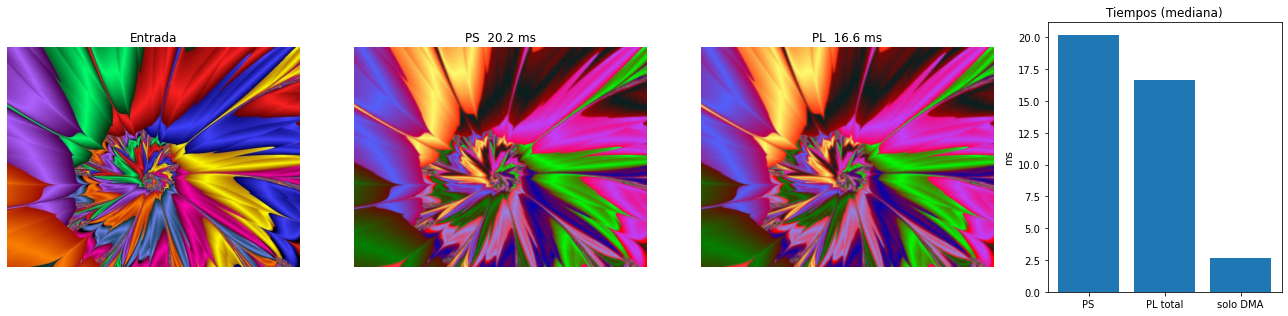

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4.5),
                       gridspec_kw={"width_ratios": [1, 1, 1, 0.8]})
for a, im, t in zip(ax[:3], [img, res_ps, res_pl],
                    ["Entrada", f"PS  {ps:.1f} ms", f"PL  {pl:.1f} ms"]):
    a.imshow(im); a.set_title(t); a.axis("off")

ax[3].bar(["PS", "PL total", "solo DMA"], [ps, pl, dm])
ax[3].set_ylabel("ms"); ax[3].set_title("Tiempos (mediana)")
plt.tight_layout(); plt.show()

In [8]:
in_buf.freebuffer(); out_buf.freebuffer()

### Prueba extensiva

  640x480      0.9 MB | PS    13.05 ms | PL    11.20 ms | DMA    2.01 ms  457.7 MB/s | x1.17 | ok=True
 1920x1080     6.2 MB | PS    92.04 ms | PL    66.46 ms | DMA    8.65 ms  718.9 MB/s | x1.38 | ok=True
 3840x2160    24.9 MB | PS   366.98 ms | PL   259.77 ms | DMA   32.02 ms  777.1 MB/s | x1.41 | ok=True
 4000x3000    36.0 MB | PS   532.89 ms | PL   374.64 ms | DMA   45.92 ms  784.0 MB/s | x1.42 | ok=True
 5000x4000    60.0 MB | PS   909.33 ms | PL   623.78 ms | DMA   75.94 ms  790.1 MB/s | x1.46 | ok=True


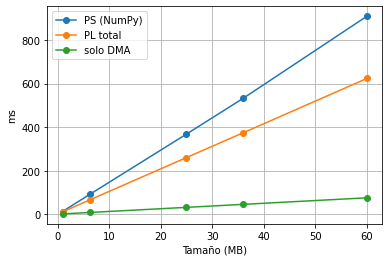

In [10]:
sizes = [(480, 640), (1080, 1920), (2160, 3840), (3000, 4000), (4000, 5000)]
res_sweep = []

for (hh, ww) in sizes:
    im = np.random.randint(0, 256, (hh, ww, 3), dtype=np.uint8)
    nn = im.size
    ib = allocate(shape=(nn,), dtype=np.uint8)
    ob = allocate(shape=(nn,), dtype=np.uint8)

    tps, tpl, tdm = [], [], []
    for _ in range(10):
        t0 = time.perf_counter(); r_ps = filtro_ps(im); tps.append(time.perf_counter() - t0)

        t0 = time.perf_counter()
        ib[:] = im.ravel(); ib.flush()
        t1 = time.perf_counter()
        dma.recvchannel.transfer(ob); dma.sendchannel.transfer(ib)
        dma.sendchannel.wait(); dma.recvchannel.wait()
        t2 = time.perf_counter()
        ob.invalidate(); r_pl = np.array(ob).reshape(hh, ww, 3)
        tpl.append(time.perf_counter() - t0); tdm.append(t2 - t1)

    ok = np.array_equal(r_ps, r_pl)
    ps, pl, dm = (np.median(x) * 1e3 for x in (tps, tpl, tdm))
    res_sweep.append((nn / 1e6, ps, pl, dm))
    print(f"{ww:5d}x{hh:<5d} {nn/1e6:6.1f} MB | PS {ps:8.2f} ms | PL {pl:8.2f} ms "
          f"| DMA {dm:7.2f} ms {nn/dm/1e3:6.1f} MB/s | x{ps/pl:4.2f} | ok={ok}")

    ib.freebuffer(); ob.freebuffer()

mb, ps, pl, dm = map(np.array, zip(*res_sweep))
plt.plot(mb, ps, "o-", label="PS (NumPy)")
plt.plot(mb, pl, "o-", label="PL total")
plt.plot(mb, dm, "o-", label="solo DMA")
plt.xlabel("Tamaño (MB)"); plt.ylabel("ms"); plt.legend(); plt.grid(True); plt.show()

### Celda de barrido por no copia de memoria

In [15]:
def bench(hh, ww, reps=10):
    ib = allocate(shape=(hh, ww, 3), dtype=np.uint8)
    ob = allocate(shape=(hh, ww, 3), dtype=np.uint8)
    ps_out = np.empty((hh, ww, 3), dtype=np.uint8)

    src = np.random.randint(0, 256, (hh, ww, 3), dtype=np.uint8)
    ib[:] = src                                   # fuera del cronómetro

    t = {k: [] for k in ("ps", "flush", "dma", "inval", "copy_in", "copy_out")}
    for _ in range(reps):
        # PS: solo cómputo, salida completa en un buffer ya reservado
        t0 = time.perf_counter()
        np.copyto(ps_out, src)
        np.subtract(255, src[:, :, 0], out=ps_out[:, :, 0])
        t["ps"].append(time.perf_counter() - t0)

        # PL: coherencia de caché + DMA, sin copias
        t0 = time.perf_counter()
        ib.flush()
        t1 = time.perf_counter()
        dma.recvchannel.transfer(ob)
        dma.sendchannel.transfer(ib)
        dma.sendchannel.wait(); dma.recvchannel.wait()
        t2 = time.perf_counter()
        ob.invalidate()
        t3 = time.perf_counter()
        t["flush"].append(t1 - t0); t["dma"].append(t2 - t1); t["inval"].append(t3 - t2)

        # Copias (solo para referencia)
        t0 = time.perf_counter(); np.copyto(ib, src);    t["copy_in"].append(time.perf_counter() - t0)
        t0 = time.perf_counter(); np.copyto(ps_out, ob); t["copy_out"].append(time.perf_counter() - t0)

    ok = np.array_equal(ob[:, :, 0], 255 - src[:, :, 0]) and np.array_equal(ob[:, :, 1:], src[:, :, 1:])
    ib.freebuffer(); ob.freebuffer()
    return {k: np.median(v) * 1e3 for k, v in t.items()}, ok


sizes = [(480, 640), (1080, 1920), (2160, 3840), (3000, 4000)]
print(f"{'tamaño':>11} {'MB':>5} | {'PS':>7} | {'flush':>6} {'DMA':>6} {'inval':>6} {'PL':>7} | "
      f"{'x total':>7} {'x DMA':>6} | {'cp_in':>6} {'cp_out':>6} | ok")
for hh, ww in sizes:
    r, ok = bench(hh, ww)
    pl = r["flush"] + r["dma"] + r["inval"]
    print(f"{ww:5d}x{hh:<5d} {hh*ww*3/1e6:5.1f} | {r['ps']:7.2f} | {r['flush']:6.2f} {r['dma']:6.2f} "
          f"{r['inval']:6.2f} {pl:7.2f} | {r['ps']/pl:7.2f} {r['ps']/r['dma']:6.2f} | "
          f"{r['copy_in']:6.2f} {r['copy_out']:6.2f} | {ok}")

     tamaño    MB |      PS |  flush    DMA  inval      PL | x total  x DMA |  cp_in cp_out | ok
  640x480     0.9 |    8.01 |   0.31   2.02   0.14    2.48 |    3.24   3.96 |   2.48   3.76 | True
 1920x1080    6.2 |   50.94 |   0.32   8.68   0.14    9.14 |    5.57   5.87 |  12.73  25.23 | True
 3840x2160   24.9 |  213.55 |   0.32  32.03   0.14   32.50 |    6.57   6.67 |  52.50 106.49 | True
 4000x3000   36.0 |  316.23 |   0.33  45.97   0.15   46.46 |    6.81   6.88 |  74.83 154.69 | True
